In [1]:
import pandas as pd
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import re
import json

from openai import OpenAI
client = OpenAI()


path = '/Users/alessiogandelli/data/cop_merged/en/topics_english.csv'
path_data = '/Users/alessiogandelli/data/cop_merged/en/tweets_labeled_en_merged.pkl'

df = pd.read_csv(path)
df = df.set_index('Topic')

df_tweets = pd.read_pickle(path_data)


# ciao questo è il titolo 

In [57]:
def topic_distribution(df_tweets, n_topics = 30, title = 'topic distribution'):

    topics = df_tweets['topic'].value_counts()
    topic_perc = topics / sum(topics)
    last_topics_sum = pd.Series(sum(topic_perc[n_topics:]))


    topics = pd.concat([topic_perc[:n_topics], last_topics_sum]).to_list()

    data = topics[1:]

    # Labels for each segment (just a simple index)
    labels = [f'Segment {i+1}' for i in range(len(data))]

    # Colors for each segment
    colors = sns.color_palette("tab10", len(data))

    # Create a DataFrame to structure the data for Seaborn
    df = pd.DataFrame({
        'Category': labels,
        'Value': data,
        'Colors': colors
    })

    # Plot the stacked bar chart
    fig, ax = plt.subplots(figsize=(5, 10))


    # Bottom values for stacking
    bottom = 0
    for i in range(len(df)):
        sns.barplot(x=['topics'], y=[df['Value'][i]], color=df['Colors'][i], bottom=bottom, ax=ax)
        bottom += df['Value'][i]

    ax.bar('outliers', topics[0], color='lightblue', alpha=0.5)


    # Add labels and title

    ax.set_ylabel('% of tweets')
    ax.set_title(title)

   # ax.text(0, 0.3,f'Topics from {n_topics} to {len(topics)}', color='black', ha='center')
    ax.text(1, 0.3, 'outliers', color='black', ha='center')
    ax.yaxis.set_major_locator(plt.MaxNLocator(30))  # Adjust the number as needed



    # Show the plot
    plt.show()

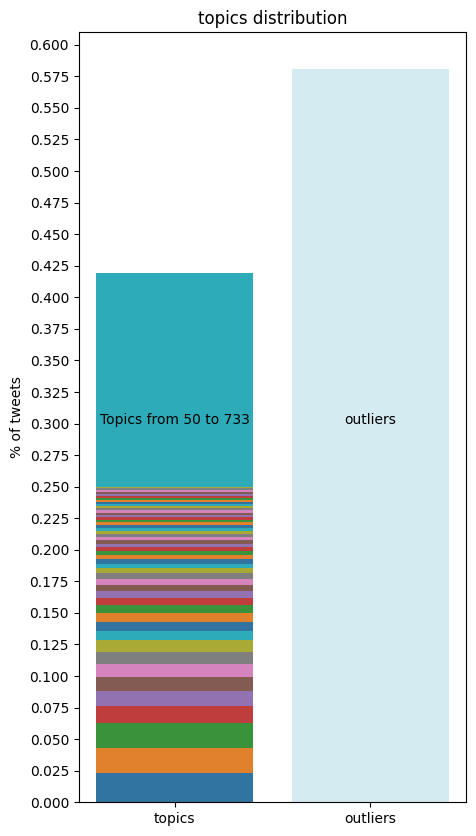

In [42]:
topic_distribution(df_tweets, n_topics=50)

In [5]:
df_first = df[1:31]



filtered_tweets = df_tweets[df_tweets['topic'].isin(df_first.index)]

print('number of tweets in the first 30 topics:', len(filtered_tweets))

numebr of tweets in the first 30 topics: 341453


In [15]:
topic_repr = {}
for n_topic in df_first.index:

    words = df_first.loc[n_topic]['Representation']

    tweets = filtered_tweets[filtered_tweets['topic'] == n_topic].sample(4)['text'].tolist()

    url_pattern = re.compile(r'https?://\S+|www\.\S+')
    tweets = [url_pattern.sub('', text) for text in tweets]


    system_prompt = """I want you to act as a tweet labeler, you are given representative words
        from a topic and four representative tweets, give more attention to the words, all the tweets are related to climate change, and COP, no need to mention it, detect subtopics.
        and avoid hashtags, reply in a json format including a short and a long label"""

    user_prompt = f"""
        which is a good label for the topic containing the words [{words}], here you are tweets to help you:
        [{tweets}]"""



    response = client.chat.completions.create(
    model="gpt-4o",
    response_format={ "type": "json_object" },
    messages=[
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_prompt}
    ]
    )

    topic = json.loads(response.choices[0].message.content)
    topic['tweets'] = tweets

    topic_repr[n_topic] = topic

df_labels = pd.DataFrame().from_dict(topic_repr).T
df_labels['words'] = df_first['Representation']
df_labels['tweet_count'] = df_first['Count']

In [17]:

for index, row in df_labels.iterrows():

    print('\n\n')

    # Print information in a structured way
    print(f"Topic {index}: {row['short_label']}")
    print(f"Long Label: {row['long_label']}")
    print(f"Keywords: {row['words']}")

    # Print the first few tweets
    print(" Tweets:")
    for i in range(3):  # Assuming you want to print the first 3 tweets
        print(f"- {row['tweets'][i]}")





Topic 0: Paris Agreement Outcomes
Long Label: Outcomes and Developments from the Paris Climate Agreement
Keywords: ['march', 'johnenglander', 'pact', '24hoursofreality', 'marching', 'vague', 'ugly', 'republicans', 'morocco', 'marrakech']
 Tweets:
- #climatechange #p2 RT President-elect Trump: Already very good for…  #COP21 #COP22 #climate #globalwarming #UNCCCF 
- The definitive @mashable guide to the Paris Climate Summit  #COP21 
- More hope for Paris climate deal after Commonwealth accord  #climate #auspol #actonclimate #cop21



Topic 1: Agriculture and Food Systems
Long Label: Impact of Agriculture and Food Systems on Climate Change
Keywords: ['meat', 'foodsystems', 'farmers', 'agriculture', 'soil', 'foodsecurity', 'food', 'agroecology', 'livestock', 'vegan']
 Tweets:
- At #COP24 on behalf of @NFUtweets @worldfarmersorg and #farmers constituency. #Koronivia and #FarmersDay ahead. Farmers #ChangingTogether for farmers 
- Follow the science and sign up to the 7-day vegan pledge, P

In [18]:
df_labels

,short_label,long_label,tweets,words,tweet_count
0,Paris Agreement Outcomes,Outcomes and Developments from the Paris Clima...,[#climatechange #p2 RT President-elect Trump: ...,"['march', 'johnenglander', 'pact', '24hoursofr...",36436
1,Agriculture and Food Systems,Impact of Agriculture and Food Systems on Clim...,[At #COP24 on behalf of @NFUtweets @worldfarme...,"['meat', 'foodsystems', 'farmers', 'agricultur...",31071
2,Airlines and Climate Impact,Airlines Mention and Their Environmental Footp...,[👀✈️🔊G-EZBC \n#Unknown \n#easyJet \n#Airbus A3...,"['easyjet', 'a320', 'ezy', '737ng', 'airbus', ...",30833
3,Event Monitoring,Monitoring and Reporting on COP Events,"[Are you at #COP22? Drop a line to Dawn, Ramsa...","['cops', 'copout', 'copout26', 'blah', 'bla', ...",21352
4,Gender and Climate Change,Impact of Climate Change on Women and Gender E...,[Out of 189 countries for which the 2018 Stati...,"['gender', 'women', 'girls', 'womens', 'gender...",18825
5,Paris Agreement Adoption,Adoption and Drafting of Paris Agreement Text ...,[@UC_Observer @dennisgruending.No magic fix fr...,"['fabius', 'laurentfabius', 'adp', 'draft', 'l...",17477
6,Canadian Climate Cities,Canadian Cities and Government Commitment to C...,[Do you need a little bit of optimism in the c...,"['billionyear', 'harjitsajjan', 'canadas', 'ca...",15701
7,Deforestation and Biodiversity,Efforts to Combat Deforestation and Promote Bi...,[Australia has joined with 100 other countries...,"['biodiversity', 'forests', 'deforestation', '...",15198
8,Sustainable Transport,Sustainable and Electric Transportation Solutions,[If you think that new #ElectricVehicles or th...,"['cycling', 'wearetransport', 'transport', 'el...",14562
9,Ocean and Ice Impact,"Impact of Climate Change on Oceans, Ice Sheets...",[#COP23: #Oceans protection priority in fight ...,"['arctic', 'ice', 'ocean', 'greenland', 'ocean...",11771


In [20]:
df_labels[['short_label', 'long_label','tweet_count']]

,short_label,long_label,tweet_count
0,Paris Agreement Outcomes,Outcomes and Developments from the Paris Clima...,36436
1,Agriculture and Food Systems,Impact of Agriculture and Food Systems on Clim...,31071
2,Airlines and Climate Impact,Airlines Mention and Their Environmental Footp...,30833
3,Event Monitoring,Monitoring and Reporting on COP Events,21352
4,Gender and Climate Change,Impact of Climate Change on Women and Gender E...,18825
5,Paris Agreement Adoption,Adoption and Drafting of Paris Agreement Text ...,17477
6,Canadian Climate Cities,Canadian Cities and Government Commitment to C...,15701
7,Deforestation and Biodiversity,Efforts to Combat Deforestation and Promote Bi...,15198
8,Sustainable Transport,Sustainable and Electric Transportation Solutions,14562
9,Ocean and Ice Impact,"Impact of Climate Change on Oceans, Ice Sheets...",11771


In [34]:
coptop = pd.DataFrame(filtered_tweets.groupby(['topic','cop'])['author'].count())

In [36]:
coptop

author
topic cop          
0     cop21   17300
      cop22    3554
      cop23    1364
      cop24    2226
      cop25    1494
...             ...
28    cop25     390
      cop26     888
      cop27     333
29    cop21    3506
      cop26       1

[201 rows x 1 columns]

(0.0, 10000.0)

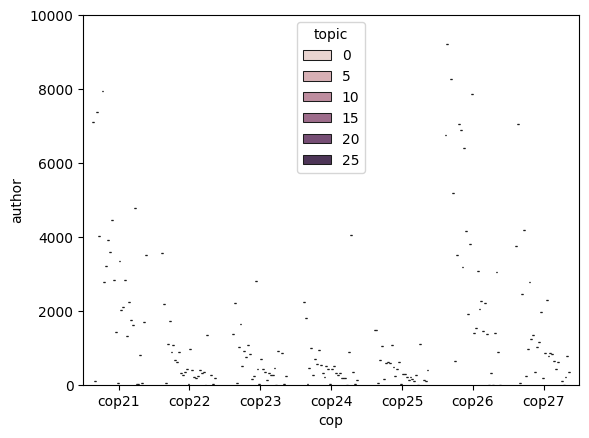

In [40]:
import seaborn as sns
sns.boxenplot(data=coptop, x='cop', y='author', hue='topic')

plt.ylim(ymin=0, ymax=10000)


# other languages 


In [67]:
path_fr = '/Users/alessiogandelli/data/cop_merged/fr/topics_fr.csv'
path_tweets_fr = '/Users/alessiogandelli/data/cop_merged/fr/tweets_cop_fr_labeled.pkl'

df_fr = pd.read_csv(path_fr)
df_fr = df_fr.set_index('Topic')

df_tweets_fr = pd.read_pickle(path_tweets_fr)



In [75]:
sum(df_fr[1:]['Count'])

274572

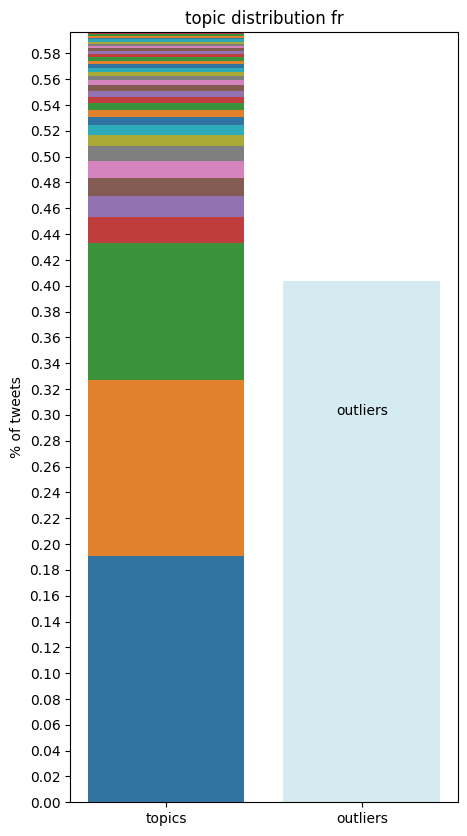

In [68]:
topic_distribution(df_tweets=df_tweets_fr, n_topics=50, title = 'topic distribution fr')

In [69]:
df

,Unnamed: 0,Count,Name,Representation,Representative_Docs
Topic,,,,,
-1,0,185867,-1_sassoui_nrcg_congo_bassin,"['sassoui', 'nrcg', 'congo', 'bassin', 'cap', ...","["".@s_guilbeault, vous avez un rôle clé à joue..."
0,1,87906,0_lemblme_contribu_httpstcoa3totustu7_partagez,"['lemblme', 'contribu', 'httpstcoa3totustu7', ...",['@Jiwan_H Bravo ! Découvrez et partagez la vi...
1,2,62574,1_climat_climatique_cop26_carbone,"['climat', 'climatique', 'cop26', 'carbone', '...","['Super reportage à Katowice, en Pologne. La v..."
2,3,48776,2_accord_paris_laccord_contraignant,"['accord', 'paris', 'laccord', 'contraignant',...",['#COP21 + que qq heures pour un accord. Notre...
3,4,9476,3_afrique_lafrique_gabon_africaine,"['afrique', 'lafrique', 'gabon', 'africaine', ...","['#Cop27 \n\nLa question de ""l\'équité climati..."
4,5,7494,4_maroc_marrakech_cop22_egypte,"['maroc', 'marrakech', 'cop22', 'egypte', 'gyp...","['Sa Majesté Le Roi #Mohammed_VI a accueilli, ..."
5,6,6349,5_enfants_jeunes_httpstco6hggeyl8tc_tudiants,"['enfants', 'jeunes', 'httpstco6hggeyl8tc', 't...","['""Dirigeants du monde entier, les jeunes s’ex..."
6,7,5973,6_lagriculture_agriculture_alimentaire_viande,"['lagriculture', 'agriculture', 'alimentaire',...","[""#COP25\n\nL'#agriculture peut atténuer les e..."
7,8,5384,7_transports_voiture_transport_mobilit,"['transports', 'voiture', 'transport', 'mobili...",['#COP21: les transports en commun seront grat...


In [79]:
path_es = '/Users/alessiogandelli/data/cop_merged/es/topics_es.csv'
path_tweets_es = '/Users/alessiogandelli/data/cop_merged/es/tweets_cop_merged_es_labeled.pkl'

df_es = pd.read_csv(path_es)
df_es = df_es.set_index('Topic')

df_tweets_es = pd.read_pickle(path_tweets_es)

In [80]:
sum(df_es[1:]['Count'])

136924

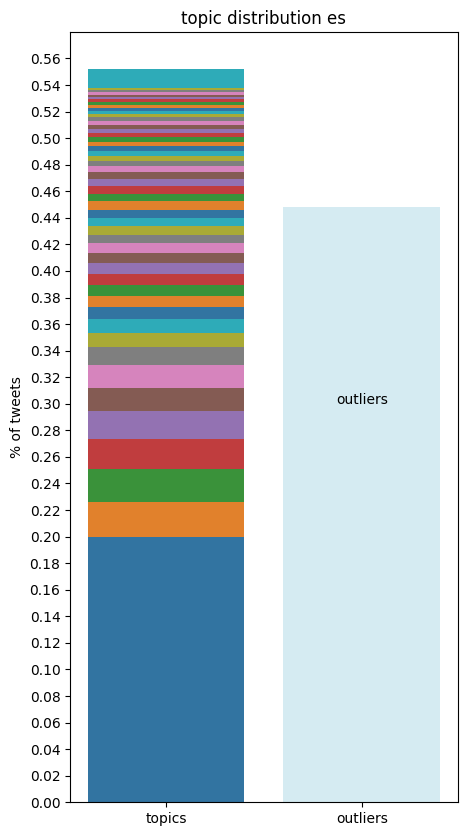

In [59]:
topic_distribution(df_tweets=df_tweets_es, n_topics=50, title = 'topic distribution es')

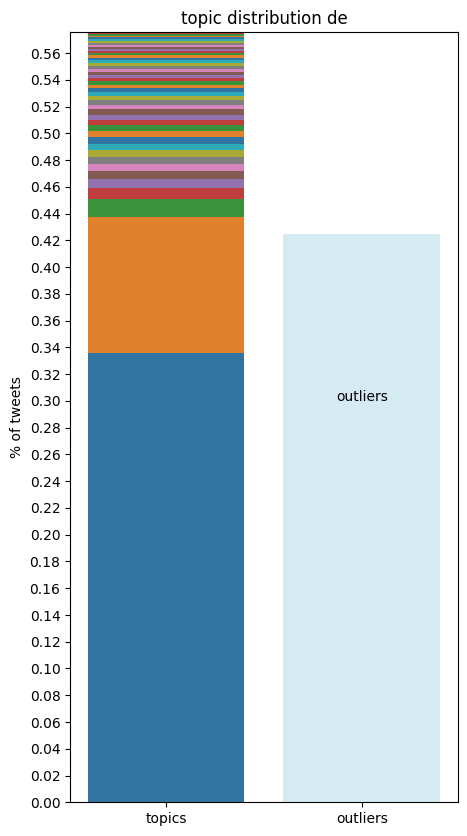

In [81]:
path_de = '/Users/alessiogandelli/data/cop_merged/de/topics_de.csv'
path_tweets_de = '/Users/alessiogandelli/data/cop_merged/de/tweet_cop_merged_de_labeled.pkl'

df_de = pd.read_csv(path_de)
df_de = df_de.set_index('Topic')

df_tweets_de = pd.read_pickle(path_tweets_de)

topic_distribution(df_tweets=df_tweets_de, n_topics=50, title = 'topic distribution de')

In [3]:
df_tweets

,author,author_name,text,date,lang,conversation_id,referenced_type,referenced_id,mentions_name,mentions_id,attachments,cop,new_text,topic,topic_prob
682712094446383104,93223785,None,Top Five #ClimateChange Videos of 2015 \nhttps...,2015-12-31 23:57:02+00:00,en,682712094446383104,None,None,[],[],None,cop21,Top Five #ClimateChange Videos of 2015 \nhttps...,-1,0.000000
682709571685621760,119572570,None,"Another February, Another Stop the War ‘Coalit...",2015-12-31 23:47:00+00:00,en,682709571685621760,None,None,[],[],None,cop21,"Another February, Another Stop the War ‘Coalit...",-1,0.000000
682706819882610688,3131302240,None,Judith Curry:2015 → 2016 #COP21 #ClimateChange...,2015-12-31 23:36:04+00:00,en,682706819882610688,None,None,[],[],None,cop21,Judith Curry:2015 → 2016 #COP21 #ClimateChange...,701,1.000000
682705520529031168,23371841,None,"Avaaz: Imperialist Pimps of Militarism, Protec...",2015-12-31 23:30:54+00:00,en,682705520529031168,None,None,[],[],None,cop21,"Avaaz: Imperialist Pimps of Militarism, Protec...",-1,0.000000
682704806759260160,3131302240,None,RealScience:1964 Global Cooling Arctic Spike W...,2015-12-31 23:28:04+00:00,en,682704806759260160,None,None,[],[],None,cop21,RealScience:1964 Global Cooling Arctic Spike W...,-1,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1578183155835580417,3901538001,None,The #climatecrisis is a water crisis. Join #Ou...,2022-10-07 00:39:20+00:00,en,1578183155835580417,None,None,[WaterAidUK],[14227045],None,cop27,The #climatecrisis is a water crisis. Join #Ou...,532,0.162031
1578183043239419904,892146157698285569,None,Livestream: Egypt’s carceral climate summit #C...,2022-10-07 00:38:53+00:00,en,1578183043239419904,None,None,[],[],None,cop27,Livestream: Egypt’s carceral climate summit #C...,-1,0.000000
1578177805413928961,1351377429177257985,None,E-waste is the fastest growing waste stream ar...,2022-10-07 00:18:04+00:00,en,1578177805413928961,None,None,"[BBCClick, UN]","[7400702, 14159148]",{'media_keys': ['3_1578172460368789510']},cop27,E-waste is the fastest growing waste stream ar...,-1,0.000000
1578177567768473600,2570515323,None,Young activists from #climatechange affected c...,2022-10-07 00:17:07+00:00,en,1578177567768473600,None,None,"[UNICEF, PlanGlobal, ChildFund, CERI_Coalition...","[33933259, 59560250, 17071011, 125226738167569...",None,cop27,Young activists from #climatechange affected c...,-1,0.000000
